In [4]:
#Imports básicos e leitura de dataset

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
csv_path = Path("../data/raw/cs-training.csv")
df = pd.read_csv(csv_path, index_col=0)

In [31]:
#Primeiras colunas do dataset
df.head()




,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [33]:
#Total de linhas do dataset

total = len(df)

print(f'Total de linhas : {total}')

Total de linhas : 150000


In [17]:
# Shape dos dados

print(f'Shape dos dados: {df.shape}')

Shape dos dados: (150000, 12)


In [38]:
#Lista de Colunas 

print(f'Colunas: {df.columns.to_list()}')


Colunas: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


In [21]:
#Tipo dos dados

print(f'Tipo de dados: {df.dtypes}')

Tipo de dados: Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object


In [41]:
#Soma de Nulos

print(f'Soma de Nulos por coluna: {df.isnull().sum()}')


print('==========================================')

#Nulos em percentil

print((df.isna().mean() * 100).round(2).sort_values(ascending=False))

Soma de Nulos por coluna: SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64
MonthlyIncome                           19.82
NumberOfDependents                       2.62
SeriousDlqin2yrs                         0.00
age                                      0.00
RevolvingUtilizationOfUnsecuredLines     0.00
DebtRatio                                0.00
NumberOfTime30-59DaysPastDueNotWorse     0.00
NumberOfOpenCreditLinesAndLoans          0.00
NumberOfTimes90DaysLate                  0.00
NumberRealEstateLoansOrLines             

In [37]:
#Soma de duplicados

print(f"Duplicados: {df.duplicated().sum()}")

Duplicados: 609


In [ ]:
#Distribuição do target

print(f'Distribuição por classe: {df["SeriousDlqin2yrs"].value_counts().sort_index()}')

Distribuição por classe: SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64


In [34]:
#Descrição estatística do dataset

df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


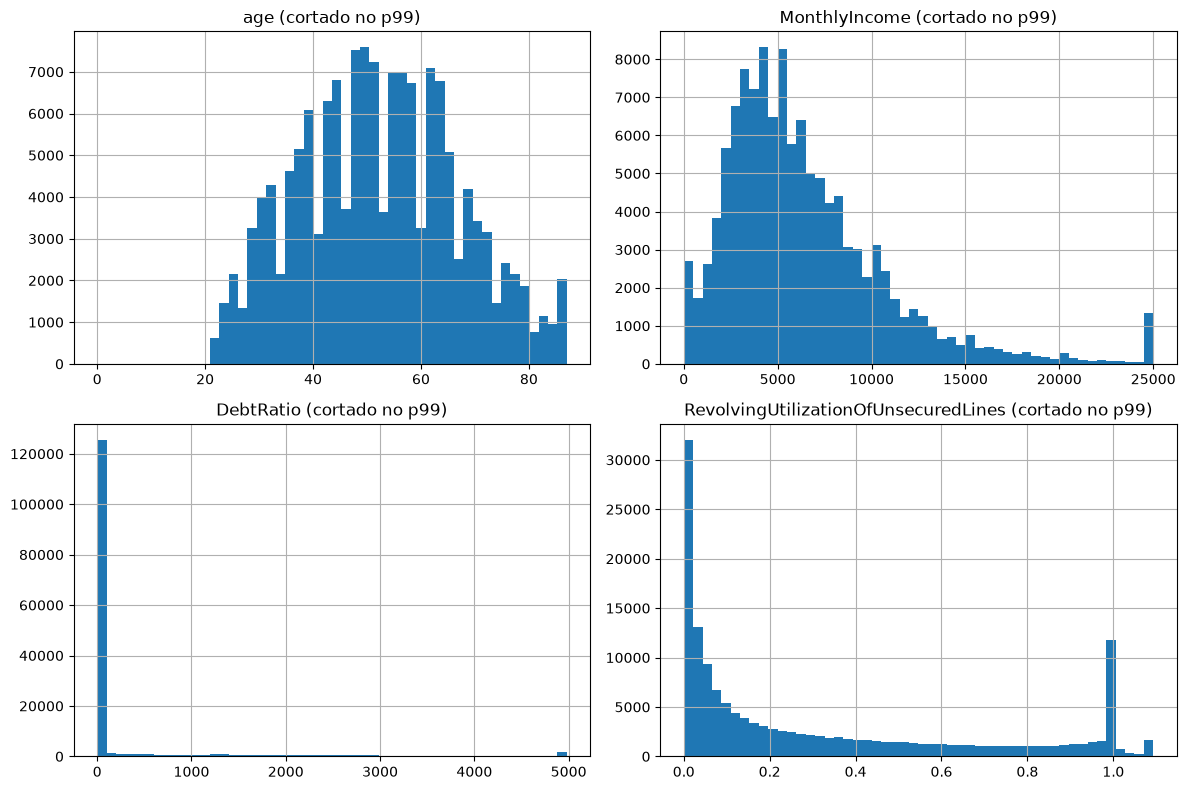

In [5]:
plot_cols = ["age", "MonthlyIncome", "DebtRatio", "RevolvingUtilizationOfUnsecuredLines"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), plot_cols):
    s = df[c].dropna()
    s.clip(upper=s.quantile(0.99)).hist(ax=ax, bins=50)
    ax.set_title(f"{c} (cortado no p99)")
plt.tight_layout()
plt.show()